In [ ]:
# Kết nối Colab với Google Drive của Thủy
from google.colab import drive
drive.mount("/content/drive")

# Kiểm tra các đường dẫn dữ liệu cần dùng
from pathlib import Path

BASE = Path("/content/drive/MyDrive/hmda")

paths = {
    "Folder hmda": BASE,
    "Quy tắc dùng chung": BASE / "rules.py",
    "Dữ liệu S1 cho RQ2": BASE / "clean_pandas" / "S1_orig_denied",
}

print("\nKIỂM TRA KẾT NỐI DỮ LIỆU")
print("-" * 45)

all_ok = True

for name, path in paths.items():
    exists = path.exists()
    print(f"{'OK' if exists else 'CHƯA TÌM THẤY'} | {name}")
    if not exists:
        all_ok = False
        print(f"  Đường dẫn đang kiểm tra: {path}")

if all_ok:
    print("\nKẾT NỐI THÀNH CÔNG — có thể chuyển sang bước đọc dữ liệu.")
else:
    print("\nChưa đủ đường dẫn. Gửi lại output này để kiểm tra tiếp.")

Mounted at /content/drive

KIỂM TRA KẾT NỐI DỮ LIỆU
---------------------------------------------
OK | Folder hmda
OK | Quy tắc dùng chung
OK | Dữ liệu S1 cho RQ2

KẾT NỐI THÀNH CÔNG — có thể chuyển sang bước đọc dữ liệu.


In [ ]:
import time
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import display

# 1. Xác định dữ liệu đầu vào
S1_PATH = "/content/drive/MyDrive/hmda/clean_pandas/S1_orig_denied"

COLS = [
    "action_taken",
    "denied_flag",
    "income",
    "debt_to_income_ratio",
    "loan_amount",
    "combined_loan_to_value_ratio",
    "property_value",
    "dti_band",
    "cltv_band",
    "loan_to_income",
]

# 2. Kiểm tra các cột cần thiết
dataset = ds.dataset(
    S1_PATH,
    format="parquet",
    partitioning="hive"
)

missing_cols = [c for c in COLS if c not in dataset.schema.names]

if missing_cols:
    raise ValueError(f"Dữ liệu đang thiếu các cột: {missing_cols}")

# 3. Đọc dữ liệu vào bảng Pandas có tên s1
print("Đang đọc dữ liệu S1...")
start = time.perf_counter()

s1 = dataset.to_table(columns=COLS).to_pandas(
    strings_to_categorical=True
)

print(f"Đọc xong sau {time.perf_counter() - start:.1f} giây.")

# 4. Kiểm tra outcome và denied_flag có khớp nhau không
action = s1["action_taken"].astype("string")
flag = pd.to_numeric(s1["denied_flag"], errors="coerce")

valid_actions = action.isin(["1", "3"]).all()
valid_flags = flag.isin([0, 1]).all()
matching_target = (
    flag.eq(action.eq("3").astype("int8")).all()
    if valid_actions and valid_flags else False
)

n_originated = int(action.eq("1").sum())
n_denied = int(action.eq("3").sum())
denial_rate = n_denied / len(s1) * 100

print("\nKIỂM TRA DỮ LIỆU")
print("-" * 50)
print(f"Tổng số dòng:       {len(s1):,}")
print(f"Originated:         {n_originated:,}")
print(f"Denied:             {n_denied:,}")
print(f"Denial rate:        {denial_rate:.2f}%")
print(f"Chỉ có outcome 1/3: {valid_actions}")
print(f"Denied flag khớp:   {matching_target}")
print(f"RAM của bảng s1:    {s1.memory_usage(deep=True).sum() / 1e9:.2f} GB")

# 5. Thống kê missing và kiểu dữ liệu
quality = pd.DataFrame({
    "data_type": s1.dtypes.astype(str),
    "missing_count": s1.isna().sum(),
    "missing_pct": (s1.isna().mean() * 100).round(2),
})

print("\nKIỂU DỮ LIỆU VÀ GIÁ TRỊ THIẾU")
display(quality)

print("\n5 DÒNG ĐẦU TIÊN")
display(s1.head())

# 6. Kết luận kiểm tra
checks_ok = (
    len(s1) == 8_300_547
    and valid_actions
    and valid_flags
    and matching_target
)

if checks_ok:
    print("\nOK — dữ liệu khớp bản bàn giao, sẵn sàng phân tích RQ2.")
else:
    print("\nCẦN KIỂM TRA — gửi lại output trước khi phân tích tiếp.")

Đang đọc dữ liệu S1...
Đọc xong sau 43.6 giây.

KIỂM TRA DỮ LIỆU
--------------------------------------------------
Tổng số dòng:       8,300,547
Originated:         6,197,085
Denied:             2,103,462
Denial rate:        25.34%
Chỉ có outcome 1/3: True
Denied flag khớp:   True
RAM của bảng s1:    0.37 GB

KIỂU DỮ LIỆU VÀ GIÁ TRỊ THIẾU


,data_type,missing_count,missing_pct
action_taken,category,0,0.00
denied_flag,int8,0,0.00
income,float64,624510,7.52
debt_to_income_ratio,category,883734,10.65
loan_amount,float64,0,0.00
combined_loan_to_value_ratio,float64,843490,10.16
property_value,float64,534689,6.44
dti_band,category,883734,10.65
cltv_band,category,843490,10.16
loan_to_income,float64,624510,7.52



5 DÒNG ĐẦU TIÊN


,action_taken,denied_flag,income,debt_to_income_ratio,loan_amount,combined_loan_to_value_ratio,property_value,dti_band,cltv_band,loan_to_income
0,1,0,NaN,NaN,295000.0,50.017,585000.0,NaN,<=60,NaN
1,1,0,NaN,NaN,265000.0,105.000,255000.0,NaN,100-250,NaN
2,3,1,NaN,NaN,275000.0,82.098,325000.0,NaN,80-90,NaN
3,1,0,NaN,NaN,375000.0,100.961,375000.0,NaN,100-250,NaN
4,1,0,NaN,NaN,305000.0,104.452,295000.0,NaN,100-250,NaN



OK — dữ liệu khớp bản bàn giao, sẵn sàng phân tích RQ2.


#Compare Financial Profiles

In [ ]:
import pandas as pd
from IPython.display import display

# Các biến cần so sánh và đơn vị gốc
VARIABLES = {
    "income": ("Income", "Thousand USD/year"),
    "loan_amount": ("Loan amount", "USD"),
    "combined_loan_to_value_ratio": ("CLTV", "%"),
    "property_value": ("Property value", "USD"),
}

GROUPS = {
    0: "Originated",
    1: "Denied",
}

rows = []

for flag, group_name in GROUPS.items():
    mask = s1["denied_flag"].eq(flag)
    total_group = int(mask.sum())

    for column, (label, unit) in VARIABLES.items():
        values = s1.loc[mask, column]

        # Các thống kê tự bỏ qua giá trị thiếu của từng biến.
        # Không xóa toàn bộ hồ sơ chỉ vì thiếu một biến.
        q = values.quantile([0.25, 0.50, 0.75])

        rows.append({
            "variable": label,
            "unit": unit,
            "outcome": group_name,
            "total_records": total_group,
            "valid_records": int(values.notna().sum()),
            "missing_pct": values.isna().mean() * 100,
            "Q1": q.loc[0.25],
            "median": q.loc[0.50],
            "Q3": q.loc[0.75],
            "IQR": q.loc[0.75] - q.loc[0.25],
        })

# Bảng đầy đủ, giữ nguyên độ chính xác để dùng ở các bước sau
rq2_summary = pd.DataFrame(rows).sort_values(
    ["variable", "outcome"]
).reset_index(drop=True)

print("BẢNG 1 — THỐNG KÊ TÀI CHÍNH THEO KẾT QUẢ HỒ SƠ")
display(rq2_summary.round(2))

# Bảng trung vị đặt hai nhóm cạnh nhau để dễ so sánh
rq2_medians = rq2_summary.pivot(
    index=["variable", "unit"],
    columns="outcome",
    values="median",
).reindex(columns=["Originated", "Denied"])

rq2_medians.columns.name = None

print("\nBẢNG 2 — SO SÁNH TRUNG VỊ")
display(rq2_medians.round(2))

# Bảng missing theo nhóm
rq2_missing = rq2_summary.pivot(
    index=["variable", "unit"],
    columns="outcome",
    values="missing_pct",
).reindex(columns=["Originated", "Denied"])

rq2_missing.columns.name = None

print("\nBẢNG 3 — TỶ LỆ THIẾU DỮ LIỆU (%)")
display(rq2_missing.round(2))

print("\nHoàn thành bước 4.")

BẢNG 1 — THỐNG KÊ TÀI CHÍNH THEO KẾT QUẢ HỒ SƠ


,variable,unit,outcome,total_records,valid_records,missing_pct,Q1,median,Q3,IQR
0,CLTV,%,Denied,2103462,1727335,17.88,53.86,74.51,87.38,33.52
1,CLTV,%,Originated,6197085,5729722,7.54,62.29,79.98,95.00,32.71
2,Income,Thousand USD/year,Denied,2103462,1950330,7.28,51.00,82.00,131.00,80.00
3,Income,Thousand USD/year,Originated,6197085,5725707,7.61,76.00,114.00,176.00,100.00
4,Loan amount,USD,Denied,2103462,2103462,0.00,65000.00,125000.00,255000.00,190000.00
5,Loan amount,USD,Originated,6197085,6197085,0.00,105000.00,235000.00,385000.00,280000.00
6,Property value,USD,Denied,2103462,1873348,10.94,205000.00,355000.00,555000.00,350000.00
7,Property value,USD,Originated,6197085,5892510,4.91,275000.00,395000.00,605000.00,330000.00



BẢNG 2 — SO SÁNH TRUNG VỊ


,,Originated,Denied
variable,unit,,
CLTV,%,79.98,74.51
Income,Thousand USD/year,114.00,82.00
Loan amount,USD,235000.00,125000.00
Property value,USD,395000.00,355000.00



BẢNG 3 — TỶ LỆ THIẾU DỮ LIỆU (%)


,,Originated,Denied
variable,unit,,
CLTV,%,7.54,17.88
Income,Thousand USD/year,7.61,7.28
Loan amount,USD,0.00,0.00
Property value,USD,4.91,10.94



Hoàn thành bước 4.


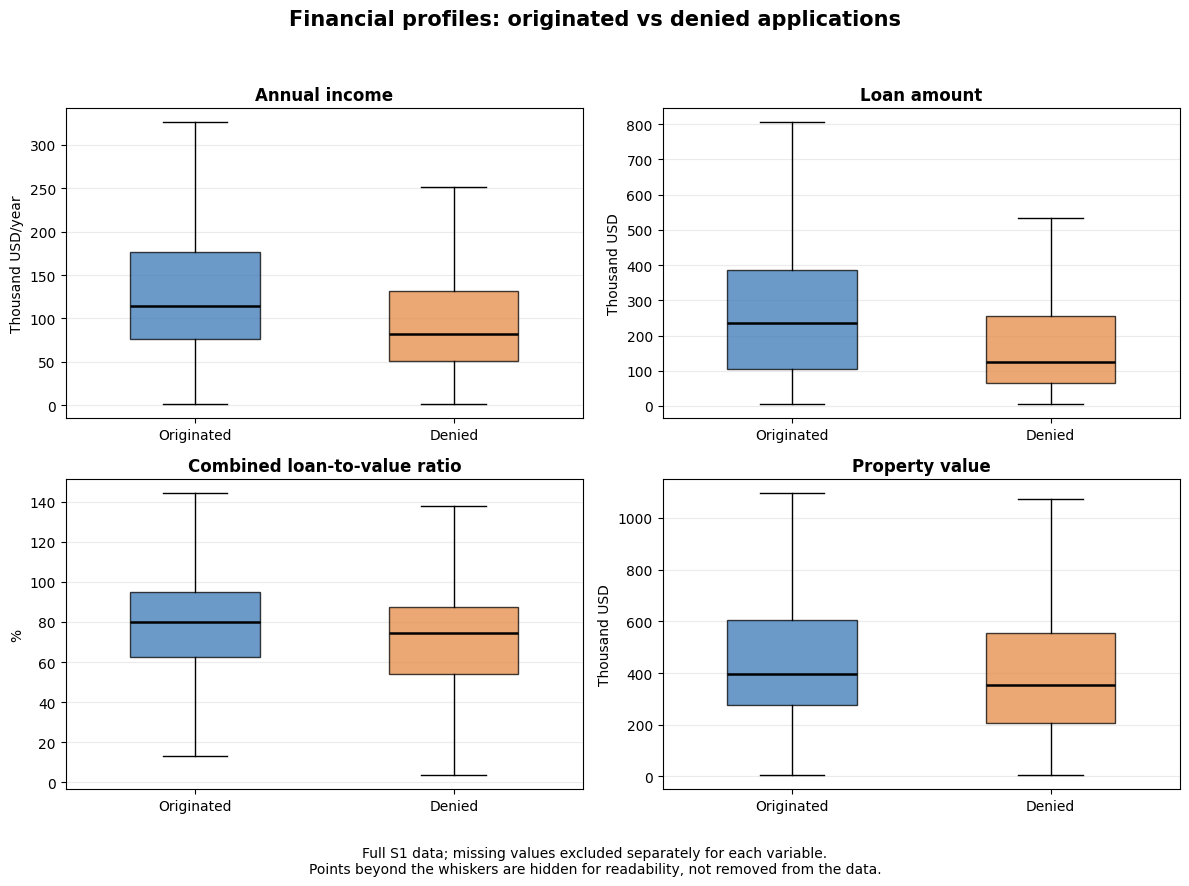

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Cột dữ liệu, tên dùng trong bảng thống kê, tiêu đề và đơn vị trên biểu đồ
PLOTS = [
    ("income", "Income", "Annual income", "Thousand USD/year", 1),
    ("loan_amount", "Loan amount", "Loan amount", "Thousand USD", 1000),
    ("combined_loan_to_value_ratio", "CLTV", "Combined loan-to-value ratio", "%", 1),
    ("property_value", "Property value", "Property value", "Thousand USD", 1000),
]

COLORS = ["#3978B8", "#E58B45"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (column, label, title, unit, divisor) in zip(axes.flat, PLOTS):
    box_stats = []

    for flag, group_name in [(0, "Originated"), (1, "Denied")]:
        # Lấy Q1, median và Q3 từ kết quả toàn bộ dữ liệu ở bước 4
        summary = rq2_summary.loc[
            (rq2_summary["variable"] == label)
            & (rq2_summary["outcome"] == group_name)
        ].iloc[0]

        q1 = float(summary["Q1"])
        median = float(summary["median"])
        q3 = float(summary["Q3"])
        iqr = q3 - q1

        values = s1.loc[s1["denied_flag"].eq(flag), column].dropna()

        # Râu hộp: giá trị thực tế nằm trong khoảng Q1/Q3 ± 1.5 × IQR
        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr
        within_whiskers = values[
            values.between(lower_limit, upper_limit)
        ]

        box_stats.append({
            "label": group_name,
            "q1": q1 / divisor,
            "med": median / divisor,
            "q3": q3 / divisor,
            "whislo": float(within_whiskers.min()) / divisor,
            "whishi": float(within_whiskers.max()) / divisor,
            "fliers": [],
        })

        del values, within_whiskers

    artists = ax.bxp(
        box_stats,
        showfliers=False,
        patch_artist=True,
        widths=0.5,
        medianprops={"color": "black", "linewidth": 1.8},
    )

    for box, color in zip(artists["boxes"], COLORS):
        box.set_facecolor(color)
        box.set_alpha(0.75)

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel(unit)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Financial profiles: originated vs denied applications",
    fontsize=15,
    fontweight="bold",
)

fig.text(
    0.5, 0.02,
    "Full S1 data; missing values excluded separately for each variable.\n"
    "Points beyond the whiskers are hidden for readability, not removed from the data.",
    ha="center", fontsize=10,
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

#Denial Rate: DTI vs CLTV

BẢNG 1 — DENIAL RATE THEO DTI


,applications,denied,originated,denial_rate_pct,share_of_S1_pct
dti_band,,,,,
<20%,432229,131641,300588,30.46,5.21
20-<30%,999770,166429,833341,16.65,12.04
30-<36%,1026750,152255,874495,14.83,12.37
36-43%,1951343,279011,1672332,14.30,23.51
44-49%,1625066,254625,1370441,15.67,19.58
50-60%,777872,311435,466437,40.04,9.37
>60%,603783,556282,47501,92.13,7.27
Missing,883734,251784,631950,28.49,10.65



BẢNG 2 — DENIAL RATE THEO CLTV


,applications,denied,originated,denial_rate_pct,share_of_S1_pct
cltv_band,,,,,
<=60,1879464,545472,1333992,29.02,22.64
60-80,2783553,604959,2178594,21.73,33.53
80-90,861463,218882,642581,25.41,10.38
90-95,556162,101000,455162,18.16,6.70
95-100,1081004,167838,913166,15.53,13.02
100-250,295411,89184,206227,30.19,3.56
Missing,843490,376127,467363,44.59,10.16


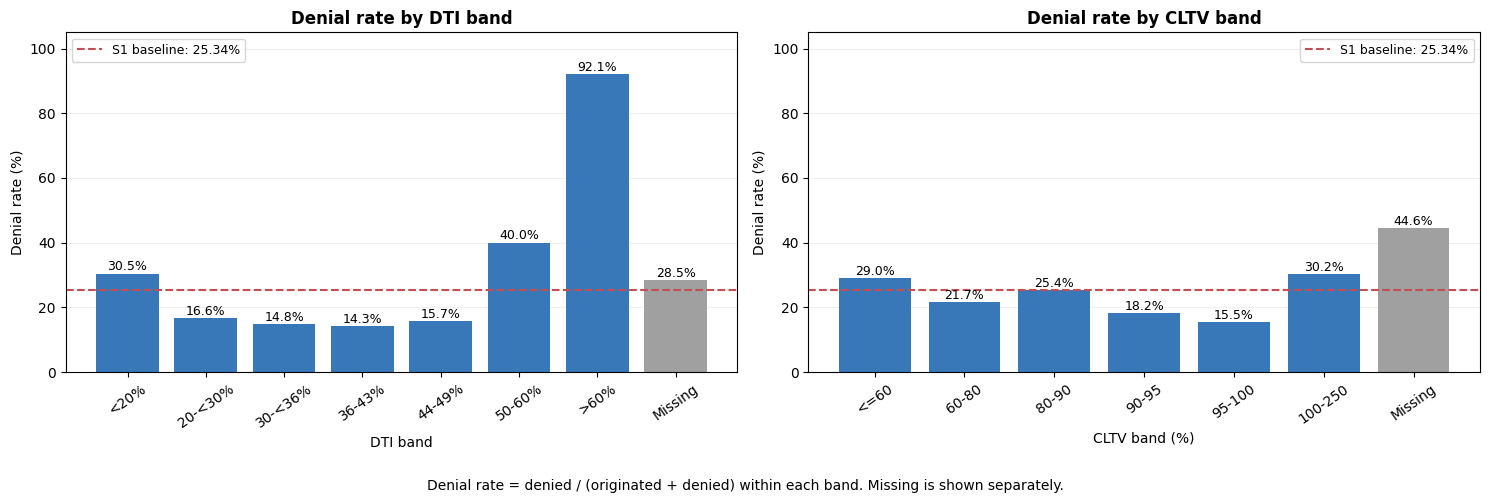


Hoàn thành bước 6 — tổng số hồ sơ và denied đều khớp S1.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Thứ tự các nhóm theo quy tắc Vanh đã dùng
DTI_ORDER = [
    "<20%", "20-<30%", "30-<36%", "36-43%",
    "44-49%", "50-60%", ">60%", "Missing"
]

CLTV_ORDER = [
    "<=60", "60-80", "80-90",
    "90-95", "95-100", "100-250", "Missing"
]

def denial_by_band(column, order):
    # Chuyển sang chuỗi để thêm nhãn Missing
    band = s1[column].astype("string").fillna("Missing")

    # Kiểm tra để không vô tình bỏ sót nhóm
    unexpected = set(band.unique()) - set(order)
    if unexpected:
        raise ValueError(f"{column} có nhãn chưa nhận diện: {unexpected}")

    table = (
        s1.groupby(band, observed=True)["denied_flag"]
        .agg(applications="size", denied="sum")
        .reindex(order)
    )

    table[["applications", "denied"]] = (
        table[["applications", "denied"]].fillna(0).astype("int64")
    )
    table["originated"] = table["applications"] - table["denied"]

    # Để NaN nếu một nhóm không có hồ sơ
    denominator = table["applications"].where(table["applications"] > 0)
    table["denial_rate_pct"] = table["denied"] / denominator * 100
    table["share_of_S1_pct"] = table["applications"] / len(s1) * 100

    # Tổng các nhóm, gồm Missing, phải bằng toàn bộ S1
    assert table["applications"].sum() == len(s1)
    assert table["denied"].sum() == s1["denied_flag"].sum()

    return table

rq2_dti = denial_by_band("dti_band", DTI_ORDER)
rq2_cltv = denial_by_band("cltv_band", CLTV_ORDER)

print("BẢNG 1 — DENIAL RATE THEO DTI")
display(rq2_dti.round(2))

print("\nBẢNG 2 — DENIAL RATE THEO CLTV")
display(rq2_cltv.round(2))

# Baseline của toàn bộ S1
baseline = s1["denied_flag"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, table, title, xlabel in [
    (axes[0], rq2_dti, "Denial rate by DTI band", "DTI band"),
    (axes[1], rq2_cltv, "Denial rate by CLTV band", "CLTV band (%)"),
]:
    colors = [
        "#A0A0A0" if label == "Missing" else "#3978B8"
        for label in table.index
    ]

    bars = ax.bar(
        table.index,
        table["denial_rate_pct"],
        color=colors
    )

    ax.axhline(
        baseline,
        color="#C44E52",
        linestyle="--",
        label=f"S1 baseline: {baseline:.2f}%"
    )

    for bar, rate in zip(bars, table["denial_rate_pct"]):
        if pd.notna(rate):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                rate + 1,
                f"{rate:.1f}%",
                ha="center",
                fontsize=9
            )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Denial rate (%)")
    ax.set_ylim(0, 105)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)

fig.text(
    0.5, 0.01,
    "Denial rate = denied / (originated + denied) within each band. "
    "Missing is shown separately.",
    ha="center", fontsize=10
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

print("\nHoàn thành bước 6 — tổng số hồ sơ và denied đều khớp S1.")

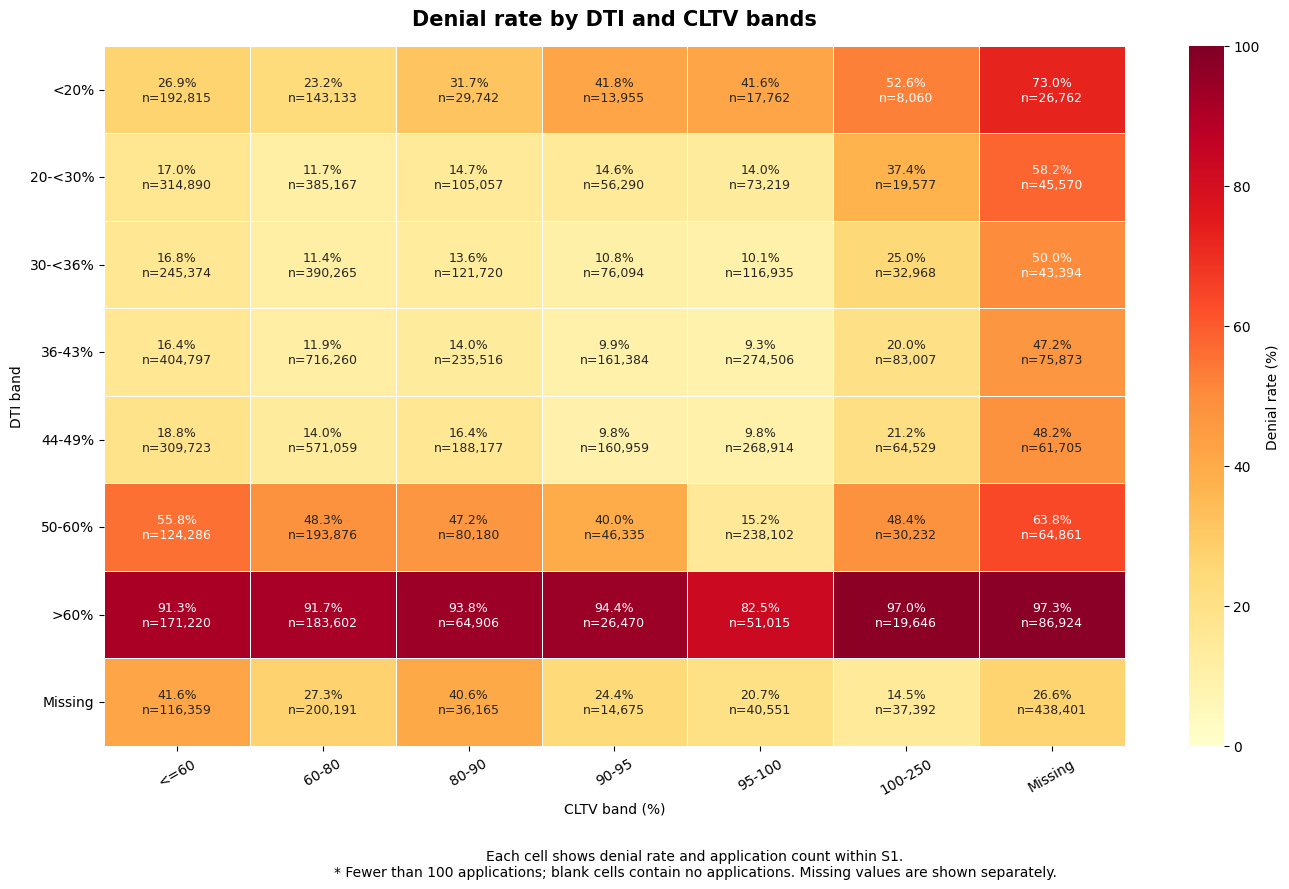

Hoàn thành bước 7 — tổng số hồ sơ và denied đều khớp S1.
Số ô có từ 1 đến 99 hồ sơ: 0


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tạo nhãn, giữ Missing thành một nhóm riêng
dti = s1["dti_band"].astype("string").fillna("Missing")
cltv = s1["cltv_band"].astype("string").fillna("Missing")

# Tổng hợp theo từng tổ hợp DTI × CLTV
rq2_joint = (
    s1.groupby([dti, cltv], observed=True)["denied_flag"]
    .agg(applications="size", denied="sum")
    .reset_index()
)

rq2_joint["denial_rate_pct"] = (
    rq2_joint["denied"] / rq2_joint["applications"] * 100
)

# Kiểm tra tổng số hồ sơ và denied
assert rq2_joint["applications"].sum() == len(s1)
assert rq2_joint["denied"].sum() == s1["denied_flag"].sum()

# Bảng tỷ lệ từ chối
rq2_heatmap_rate = rq2_joint.pivot(
    index="dti_band",
    columns="cltv_band",
    values="denial_rate_pct"
).reindex(index=DTI_ORDER, columns=CLTV_ORDER)

# Bảng số hồ sơ, cùng vị trí với bảng tỷ lệ
rq2_heatmap_n = rq2_joint.pivot(
    index="dti_band",
    columns="cltv_band",
    values="applications"
).reindex(index=DTI_ORDER, columns=CLTV_ORDER).fillna(0).astype("int64")

# Nội dung hiển thị trong từng ô
annotations = pd.DataFrame(
    "", index=DTI_ORDER, columns=CLTV_ORDER
)

for row in DTI_ORDER:
    for col in CLTV_ORDER:
        n = rq2_heatmap_n.loc[row, col]
        rate = rq2_heatmap_rate.loc[row, col]

        if n > 0:
            # Dấu * giúp nhận diện ô ít hồ sơ
            marker = "*" if n < 100 else ""
            annotations.loc[row, col] = (
                f"{rate:.1f}%{marker}\nn={n:,}"
            )

# Vẽ heatmap
fig, ax = plt.subplots(figsize=(14, 9))

sns.heatmap(
    rq2_heatmap_rate,
    annot=annotations,
    fmt="",
    mask=rq2_heatmap_n.eq(0),
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    annot_kws={"fontsize": 9},
    cbar_kws={"label": "Denial rate (%)"},
    ax=ax,
)

ax.set_title(
    "Denial rate by DTI and CLTV bands",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("CLTV band (%)")
ax.set_ylabel("DTI band")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)

fig.text(
    0.5, 0.02,
    "Each cell shows denial rate and application count within S1.\n"
    "* Fewer than 100 applications; blank cells contain no applications. "
    "Missing values are shown separately.",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

print("Hoàn thành bước 7 — tổng số hồ sơ và denied đều khớp S1.")
print("Số ô có từ 1 đến 99 hồ sơ:",
      int(((rq2_heatmap_n > 0) & (rq2_heatmap_n < 100)).sum().sum()))

Đang tính Spearman trên toàn bộ S1, có thể mất một lúc...

BẢNG 1 — TƯƠNG QUAN SPEARMAN


,Income,Loan amount,CLTV,Property value,Denied flag
Income,1.000,0.460,0.006,0.631,-0.213
Loan amount,0.460,1.000,0.307,0.520,-0.234
CLTV,0.006,0.307,1.000,-0.246,-0.095
Property value,0.631,0.520,-0.246,1.000,-0.097
Denied flag,-0.213,-0.234,-0.095,-0.097,1.000



BẢNG 2 — SỐ HỒ SƠ ĐƯỢC DÙNG CHO TỪNG CẶP


,Income,Loan amount,CLTV,Property value,Denied flag
Income,7676037,7676037,7018034,7300715,7676037
Loan amount,7676037,8300547,7457057,7765858,8300547
CLTV,7018034,7457057,7457057,7387807,7457057
Property value,7300715,7765858,7387807,7765858,7765858
Denied flag,7676037,8300547,7457057,7765858,8300547



BẢNG 3 — LIÊN HỆ VỚI DENIED FLAG


,spearman_with_denied,valid_pairs
Income,-0.213,7676037
Loan amount,-0.234,8300547
CLTV,-0.095,7457057
Property value,-0.097,7765858


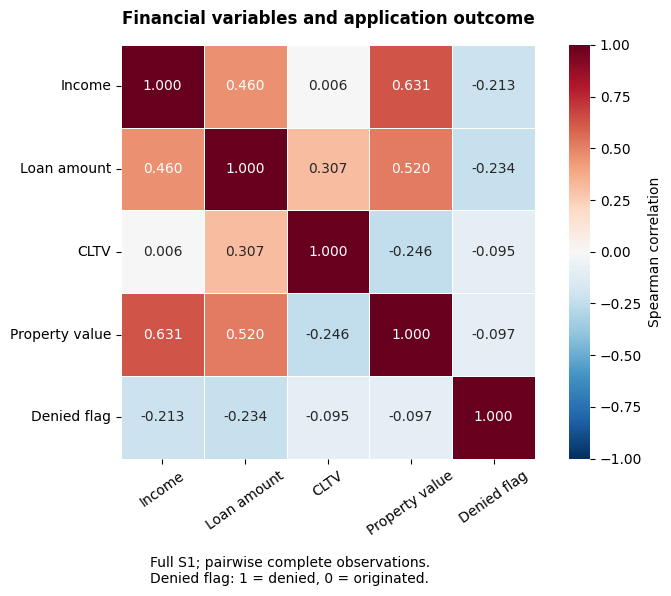


Hoàn thành bước 8.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

CORR_COLS = [
    "income",
    "loan_amount",
    "combined_loan_to_value_ratio",
    "property_value",
    "denied_flag",
]

LABELS = {
    "income": "Income",
    "loan_amount": "Loan amount",
    "combined_loan_to_value_ratio": "CLTV",
    "property_value": "Property value",
    "denied_flag": "Denied flag",
}

print("Đang tính Spearman trên toàn bộ S1, có thể mất một lúc...")

# Mỗi cặp sử dụng những hồ sơ có đủ cả hai biến.
# Không điền missing và không lấy mẫu.
rq2_spearman = s1[CORR_COLS].corr(method="spearman")

# Đếm số hồ sơ thực tế được dùng cho từng cặp biến
valid = s1[CORR_COLS].notna()

rq2_corr_n = pd.DataFrame(
    0, index=CORR_COLS, columns=CORR_COLS, dtype="int64"
)

for i, col_a in enumerate(CORR_COLS):
    for col_b in CORR_COLS[i:]:
        n = int((valid[col_a] & valid[col_b]).sum())
        rq2_corr_n.loc[col_a, col_b] = n
        rq2_corr_n.loc[col_b, col_a] = n

del valid

print("\nBẢNG 1 — TƯƠNG QUAN SPEARMAN")
display(
    rq2_spearman.rename(index=LABELS, columns=LABELS).round(3)
)

print("\nBẢNG 2 — SỐ HỒ SƠ ĐƯỢC DÙNG CHO TỪNG CẶP")
display(
    rq2_corr_n.rename(index=LABELS, columns=LABELS)
)

# Bảng riêng: tương quan từng biến tài chính với outcome
rq2_corr_target = pd.DataFrame({
    "spearman_with_denied": rq2_spearman.loc[
        CORR_COLS[:-1], "denied_flag"
    ],
    "valid_pairs": rq2_corr_n.loc[
        CORR_COLS[:-1], "denied_flag"
    ],
}).rename(index=LABELS)

print("\nBẢNG 3 — LIÊN HỆ VỚI DENIED FLAG")
display(rq2_corr_target.round(3))

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    rq2_spearman.rename(index=LABELS, columns=LABELS),
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"},
    ax=ax,
)

ax.set_title(
    "Financial variables and application outcome",
    fontweight="bold",
    pad=15,
)
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)

fig.text(
    0.5, 0.02,
    "Full S1; pairwise complete observations.\n"
    "Denied flag: 1 = denied, 0 = originated.",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

print("\nHoàn thành bước 8.")

In [ ]:
from pathlib import Path
import pandas as pd

# Lưu kết quả riêng trong Drive của Thủy
# Folder dữ liệu chung hmda của Vanh không bị thay đổi
RQ2_OUT = Path("/content/drive/MyDrive/HMDA_Thuy/rq2_pandas")
TABLES_OUT = RQ2_OUT / "tables"
TABLES_OUT.mkdir(parents=True, exist_ok=True)

# Danh sách các bảng đã tạo
TABLES = {
    "01_financial_summary.csv": rq2_summary,
    "02_median_comparison.csv": rq2_medians,
    "03_missing_by_outcome.csv": rq2_missing,
    "04_denial_by_dti.csv": rq2_dti,
    "05_denial_by_cltv.csv": rq2_cltv,
    "06_dti_cltv_joint_results.csv": rq2_joint,
    "07_dti_cltv_denial_rate_matrix.csv": rq2_heatmap_rate,
    "08_dti_cltv_count_matrix.csv": rq2_heatmap_n,
    "09_spearman_matrix.csv": rq2_spearman,
    "10_spearman_pair_counts.csv": rq2_corr_n,
    "11_spearman_with_denied.csv": rq2_corr_target,
}

# Hai bảng này đã có các nhãn cần thiết dưới dạng cột,
# nên không cần ghi thêm index.
NO_INDEX = {
    "01_financial_summary.csv",
    "06_dti_cltv_joint_results.csv",
}

print("ĐANG LƯU KẾT QUẢ")
print("-" * 55)

for filename, table in TABLES.items():
    path = TABLES_OUT / filename

    # Lưu số liệu gốc, không làm tròn trước khi xuất
    table.to_csv(
        path,
        index=filename not in NO_INDEX,
        encoding="utf-8-sig",
    )

    # Đọc lại để kiểm tra file đã ghi đủ số dòng
    saved = pd.read_csv(path)
    assert len(saved) == len(table), f"File chưa khớp: {filename}"

    print(f"OK | {filename}")

# Lưu thông tin tập dữ liệu để người nhận biết phạm vi phân tích
sample_info = pd.DataFrame([{
    "sample": "S1: originated and denied",
    "total_records": len(s1),
    "originated": int(s1["denied_flag"].eq(0).sum()),
    "denied": int(s1["denied_flag"].eq(1).sum()),
    "denial_rate_pct": s1["denied_flag"].mean() * 100,
    "source": "/content/drive/MyDrive/hmda/clean_pandas/S1_orig_denied",
    "engine": "Pandas",
}])

sample_info.to_csv(
    TABLES_OUT / "00_sample_info.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nĐÃ LƯU VÀ KIỂM TRA 12 FILE CSV.")
print("Vị trí trong Google Drive:")
print("My Drive → HMDA_Thuy → rq2_pandas → tables")

ĐANG LƯU KẾT QUẢ
-------------------------------------------------------
OK | 01_financial_summary.csv
OK | 02_median_comparison.csv
OK | 03_missing_by_outcome.csv
OK | 04_denial_by_dti.csv
OK | 05_denial_by_cltv.csv
OK | 06_dti_cltv_joint_results.csv
OK | 07_dti_cltv_denial_rate_matrix.csv
OK | 08_dti_cltv_count_matrix.csv
OK | 09_spearman_matrix.csv
OK | 10_spearman_pair_counts.csv
OK | 11_spearman_with_denied.csv

ĐÃ LƯU VÀ KIỂM TRA 12 FILE CSV.
Vị trí trong Google Drive:
My Drive → HMDA_Thuy → rq2_pandas → tables


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES_OUT = Path("/content/drive/MyDrive/HMDA_Thuy/rq2_pandas/figures")
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

def save_figure(fig, filename):
    path = FIGURES_OUT / filename
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"Đã lưu: {filename}")

# ==================================================
# HÌNH 1 — BOXPLOT
# ==================================================
plots = [
    ("income", "Income", "Annual income", "Thousand USD/year", 1),
    ("loan_amount", "Loan amount", "Loan amount", "Thousand USD", 1000),
    ("combined_loan_to_value_ratio", "CLTV",
     "Combined loan-to-value ratio", "%", 1),
    ("property_value", "Property value",
     "Property value", "Thousand USD", 1000),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (column, label, title, unit, divisor) in zip(axes.flat, plots):
    stats = []

    for flag, name in [(0, "Originated"), (1, "Denied")]:
        row = rq2_summary.loc[
            (rq2_summary["variable"] == label)
            & (rq2_summary["outcome"] == name)
        ].iloc[0]

        q1, med, q3 = [float(row[k]) for k in ["Q1", "median", "Q3"]]
        iqr = q3 - q1
        values = s1.loc[s1["denied_flag"].eq(flag), column].dropna()
        inside = values[values.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)]

        stats.append({
            "label": name,
            "q1": q1 / divisor,
            "med": med / divisor,
            "q3": q3 / divisor,
            "whislo": float(inside.min()) / divisor,
            "whishi": float(inside.max()) / divisor,
            "fliers": [],
        })
        del values, inside

    artists = ax.bxp(
        stats, showfliers=False, patch_artist=True, widths=0.5,
        medianprops={"color": "black", "linewidth": 1.8}
    )
    for box, color in zip(artists["boxes"], ["#3978B8", "#E58B45"]):
        box.set_facecolor(color)
        box.set_alpha(0.75)

    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(unit)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Financial profiles: originated vs denied applications",
    fontsize=15, fontweight="bold"
)
fig.text(
    0.5, 0.02,
    "Full S1; missing values excluded separately for each variable.\n"
    "Points beyond the whiskers are hidden, not removed from the data.",
    ha="center", fontsize=10
)
fig.tight_layout(rect=[0, 0.07, 1, 0.95])
save_figure(fig, "01_financial_boxplots.png")

# ==================================================
# HÌNH 2 — DENIAL RATE THEO DTI / CLTV
# ==================================================
baseline = s1["denied_flag"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, table, title, xlabel in [
    (axes[0], rq2_dti, "Denial rate by DTI band", "DTI band"),
    (axes[1], rq2_cltv, "Denial rate by CLTV band", "CLTV band (%)"),
]:
    colors = [
        "#A0A0A0" if label == "Missing" else "#3978B8"
        for label in table.index
    ]
    bars = ax.bar(table.index, table["denial_rate_pct"], color=colors)
    ax.axhline(
        baseline, color="#C44E52", linestyle="--",
        label=f"S1 baseline: {baseline:.2f}%"
    )
    for bar, rate in zip(bars, table["denial_rate_pct"]):
        if pd.notna(rate):
            ax.text(
                bar.get_x() + bar.get_width() / 2, rate + 1,
                f"{rate:.1f}%", ha="center", fontsize=9
            )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Denial rate (%)")
    ax.set_ylim(0, 105)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)

fig.text(
    0.5, 0.01,
    "Denial rate = denied / (originated + denied) within each band. "
    "Missing is shown separately.",
    ha="center", fontsize=10
)
fig.tight_layout(rect=[0, 0.06, 1, 1])
save_figure(fig, "02_denial_by_dti_cltv.png")

# ==================================================
# HÌNH 3 — HEATMAP DTI × CLTV
# ==================================================
annotations = pd.DataFrame(
    "", index=rq2_heatmap_rate.index, columns=rq2_heatmap_rate.columns
)

for row in annotations.index:
    for col in annotations.columns:
        n = rq2_heatmap_n.loc[row, col]
        if n > 0:
            rate = rq2_heatmap_rate.loc[row, col]
            marker = "*" if n < 100 else ""
            annotations.loc[row, col] = f"{rate:.1f}%{marker}\nn={n:,}"

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(
    rq2_heatmap_rate, annot=annotations, fmt="",
    mask=rq2_heatmap_n.eq(0),
    cmap="YlOrRd", vmin=0, vmax=100, linewidths=0.5,
    annot_kws={"fontsize": 9},
    cbar_kws={"label": "Denial rate (%)"}, ax=ax
)
ax.set_title("Denial rate by DTI and CLTV bands",
             fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("CLTV band (%)")
ax.set_ylabel("DTI band")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)
fig.text(
    0.5, 0.02,
    "Each cell shows denial rate and application count within S1.\n"
    "* Fewer than 100 applications; blank cells contain no applications. "
    "Missing is shown separately.",
    ha="center", fontsize=10
)
fig.tight_layout(rect=[0, 0.07, 1, 1])
save_figure(fig, "03_dti_cltv_heatmap.png")

# ==================================================
# HÌNH 4 — SPEARMAN
# ==================================================
labels = {
    "income": "Income",
    "loan_amount": "Loan amount",
    "combined_loan_to_value_ratio": "CLTV",
    "property_value": "Property value",
    "denied_flag": "Denied flag",
}

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    rq2_spearman.rename(index=labels, columns=labels),
    annot=True, fmt=".3f", cmap="RdBu_r",
    vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"}, ax=ax
)
ax.set_title("Financial variables and application outcome",
             fontweight="bold", pad=15)
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)
fig.text(
    0.5, 0.02,
    "Full S1; pairwise complete observations.\n"
    "Denied flag: 1 = denied, 0 = originated.",
    ha="center", fontsize=10
)
fig.tight_layout(rect=[0, 0.07, 1, 1])
save_figure(fig, "04_spearman_heatmap.png")

# Kiểm tra đủ file và file không rỗng
expected = [
    "01_financial_boxplots.png",
    "02_denial_by_dti_cltv.png",
    "03_dti_cltv_heatmap.png",
    "04_spearman_heatmap.png",
]
assert all(
    (FIGURES_OUT / name).is_file()
    and (FIGURES_OUT / name).stat().st_size > 0
    for name in expected
)

print("\nHOÀN THÀNH — đã lưu đủ 4 hình.")
print("My Drive → HMDA_Thuy → rq2_pandas → figures")

Đã lưu: 01_financial_boxplots.png
Đã lưu: 02_denial_by_dti_cltv.png
Đã lưu: 03_dti_cltv_heatmap.png
Đã lưu: 04_spearman_heatmap.png

HOÀN THÀNH — đã lưu đủ 4 hình.
My Drive → HMDA_Thuy → rq2_pandas → figures


RQ2 examines financial differences between originated and denied applications using 8,300,547 records, with a baseline denial rate of 25.34%. Median annual income was $114,000 for originated applications and $82,000 for denied applications. Median loan amounts were $235,000 and $125,000, respectively, while median property values were $395,000 and $355,000. These comparisons describe differences between the observed groups rather than the independent effects of individual financial characteristics.

Denial rates rose sharply across the higher DTI bands: 14.30% for DTI of 36–43%, 40.04% for 50–60%, and 92.13% for above 60%. However, the relationship was not uniformly increasing, as the below-20% group also had an elevated denial rate of 30.46%. Across CLTV bands with reported values, applications with DTI above 60% consistently showed high denial rates, ranging from approximately 82.5% to 97.0%.

CLTV showed a more complex pattern. Within the DTI 50–60% band, the CLTV 95–100% group had a denial rate of only 15.2%, based on 238,102 applications. This finding warrants further examination by loan type, purpose and lender before interpretation. Missing CLTV was also associated with a high denial rate of 44.59%; CLTV missingness differed substantially between denied applications (17.88%) and originated applications (7.54%).

Spearman correlations with denial were −0.213 for income, −0.234 for loan amount, −0.095 for CLTV and −0.097 for property value. These pairwise associations do not control for other application characteristics and may conceal non-monotonic patterns. Overall, the results identify financial profiles for further investigation, while product composition, lender differences and missing information limit causal interpretation.